# 09 Feature Selection
Every model so far uses all 76 pre-game features, and every model stops at about 66% on validation. Here we test whether a **small set of features** carries the same signal.

Methods:
1. **Redundancy filter:** drop near-duplicate features (correlation above 0.95).
2. **Filter method:** mutual information between each feature and the label.
3. **Embedded method:** L1 (lasso) logistic regression, which sets weak features' weights to exactly 0.
4. **Model-based importance:** permutation importance.
5. **How many features do we need?** Score models on the top-k features.
6. **Final check:** selected features vs all 76 for logistic regression, random forest and both SVMs.

**Leakage rule:** every ranking that feeds a score is fitted on training rows only. Validation (2017-18) is only used for the final check. Test (2019-22) stays reserved.

### Step 1: imports, data, split and evaluation (same as the other model notebooks)

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

data = pd.read_csv("../src/dataset/model_table.csv", parse_dates=["GAME_DATE"])
feature_cols = [c for c in data.columns if c not in ("GAME_DATE", "SEASON", "SPLIT", "HOME_TEAM_WINS")]
X = data[feature_cols]
y = data["HOME_TEAM_WINS"]
is_train, is_val, is_test = (data["SPLIT"] == s for s in ("train", "validation", "test"))
season = data["SEASON"]

def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

# forward-chaining folds inside the training seasons (same as notebooks 04, 05, 08)
fold_seasons = [2012, 2013, 2014, 2015, 2016]
def folds():
    for s in fold_seasons:
        yield s, is_train & (season < s), is_train & (season == s)

# the models from notebooks 05, 06 and 08, with their chosen settings
def lr_model(C=0.01, l1=False):
    lr = (LogisticRegression(C=C, l1_ratio=1.0, solver="liblinear", max_iter=10000) if l1
          else LogisticRegression(C=C, max_iter=10000))
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", lr)])

def rf_model():
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("model", RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20,
                                                      random_state=42, n_jobs=-1))])

def svm_model(kernel, C, gamma="scale"):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
                     ("model", SVC(kernel=kernel, C=C, gamma=gamma, probability=True, random_state=42))])

print(len(feature_cols), "features |", int(is_train.sum()), "train games |", int(is_val.sum()), "validation games")

76 features | 18110 train games | 2624 validation games


### Step 2: redundancy filter
Pairs of features with |correlation| above 0.95 on the training seasons carry almost the same information. For each pair we keep the first one (in column order). This rule does not look at the label.

In [2]:
corr = X[is_train].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)

drop = []
for (a, b), r in pairs.items():
    if a not in drop and b not in drop:
        drop.append(b)
kept = [c for c in feature_cols if c not in drop]

print(len(pairs), "pairs above 0.95 ->", len(drop), "features dropped,", len(kept), "kept")
pairs.round(4).to_frame("|correlation|")

10 pairs above 0.95 -> 7 features dropped, 69 kept


|correlation|
AWAY_SEASON_W_PCT AWAY_ST_W_PCT         0.9999
HOME_SEASON_W_PCT HOME_ST_W_PCT         0.9999
DIFF_SEASON_W_PCT DIFF_ST_W_PCT         0.9998
HOME_SEASON_G     AWAY_SEASON_G         0.9983
HOME_ST_G         AWAY_ST_G             0.9983
AWAY_SEASON_G     AWAY_ST_G             0.9969
HOME_SEASON_G     HOME_ST_G             0.9969
                  AWAY_ST_G             0.9953
HOME_ST_G         AWAY_SEASON_G         0.9952
ELO_PROB_HOME     DIFF_ELO              0.9896

### Step 3: filter method, mutual information
Mutual information measures how much knowing a feature tells us about who wins (0 = nothing). It catches non-linear relationships too. Computed on the training seasons only, after filling missing values with training medians.

mutual information computed in 2.8s


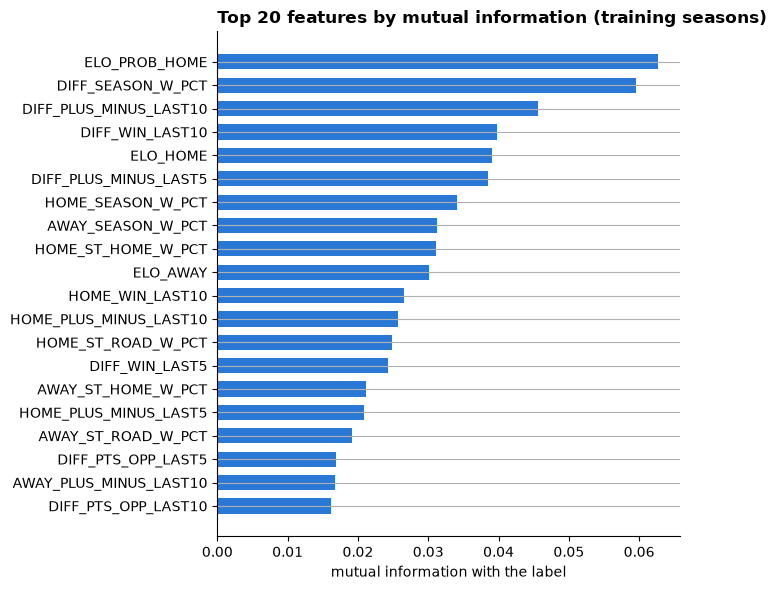

In [3]:
def mi_rank(X_fit, y_fit, cols):
    filled = X_fit[cols].fillna(X_fit[cols].median())
    mi = mutual_info_classif(filled, y_fit, random_state=42)
    return pd.Series(mi, index=cols).sort_values(ascending=False)

t0 = time.time()
mi_train = mi_rank(X[is_train], y[is_train], kept)
print("mutual information computed in %.1fs" % (time.time() - t0))

top = mi_train.head(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=BLUE, height=0.65)
ax.set_xlabel("mutual information with the label"); ax.grid(axis="y")
ax.set_title("Top 20 features by mutual information (training seasons)")
plt.tight_layout(); plt.show()

### Step 4: embedded method, L1 (lasso) logistic regression
L1 regularization pushes the weights of weak features to exactly 0, so the model selects features while it trains. A smaller C keeps fewer features. C is tuned with the forward-chaining folds (lowest mean fold log loss).

In [4]:
rows = []
for C in [0.001, 0.003, 0.01, 0.03, 0.1, 1.0]:
    fold_ll = []
    for s, fit_mask, score_mask in folds():
        m = lr_model(C, l1=True).fit(X.loc[fit_mask, feature_cols], y[fit_mask])
        fold_ll.append(log_loss(y[score_mask], m.predict_proba(X.loc[score_mask, feature_cols])[:, 1]))
    full = lr_model(C, l1=True).fit(X.loc[is_train, feature_cols], y[is_train])
    rows.append({"C": C, "fold_log_loss_mean": np.mean(fold_ll),
                 "features_kept": int((full.named_steps["model"].coef_ != 0).sum())})
l1_tuning = pd.DataFrame(rows)
best_C = l1_tuning.sort_values(["fold_log_loss_mean", "C"]).iloc[0]["C"]

l1 = lr_model(best_C, l1=True).fit(X.loc[is_train, feature_cols], y[is_train])
l1_coef = pd.Series(l1.named_steps["model"].coef_[0], index=feature_cols)
l1_selected = l1_coef[l1_coef != 0].abs().sort_values(ascending=False)
print(f"best C = {best_C}: L1 keeps {len(l1_selected)} of {len(feature_cols)} features")
display(l1_tuning.round(4))
l1_selected.round(4).to_frame("|weight| (standardized)")

best C = 0.03: L1 keeps 35 of 76 features


,C,fold_log_loss_mean,features_kept
0,0.001,0.6276,3
1,0.003,0.6059,5
2,0.010,0.6024,13
3,0.030,0.6015,35
4,0.100,0.6022,44
5,1.000,0.6035,54


,|weight| (standardized)
DIFF_ELO,0.6338
DIFF_PLUS_MINUS_LAST10,0.1565
DIFF_PLUS_MINUS_LAST5,0.1044
HOME_ST_W,0.0984
AWAY_BACK_TO_BACK,0.0922
HOME_WIN_LAST5,0.0721
HOME_ST_HOME_W_PCT,0.0657
HOME_BACK_TO_BACK,0.0649
DIFF_WIN_LAST5,0.0517
DIFF_WIN_LAST10,0.0490


### Step 5: permutation importance
How much worse does the model get if one feature is shuffled? Logistic regression (C = 0.01, notebook 05) is trained on 2003-2015 and scored on 2016, the last training season, so validation stays untouched. Importance = increase in log loss, averaged over 10 shuffles.

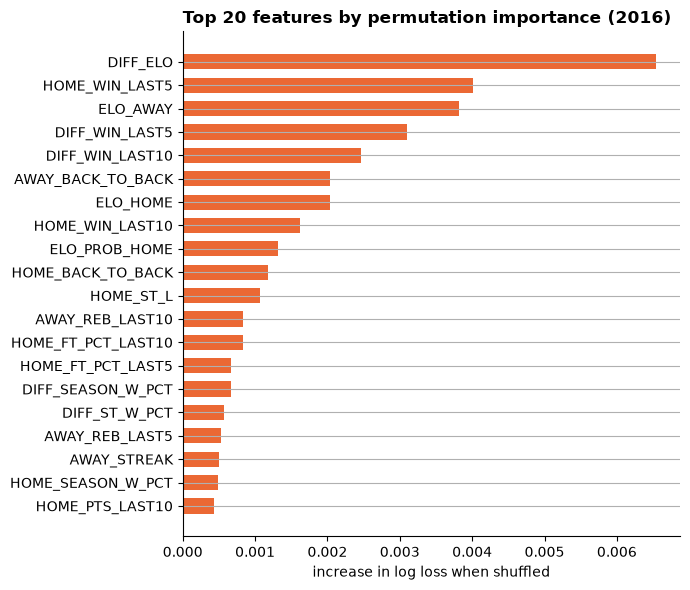

in the top 10 of all three methods: ['DIFF_WIN_LAST10']


In [5]:
fit_mask, hold = is_train & (season < 2016), is_train & (season == 2016)
lr16 = lr_model(0.01).fit(X.loc[fit_mask, feature_cols], y[fit_mask])
pi = permutation_importance(lr16, X.loc[hold, feature_cols], y[hold], scoring="neg_log_loss",
                            n_repeats=10, random_state=42)
perm = pd.Series(pi.importances_mean, index=feature_cols).sort_values(ascending=False)

top = perm.head(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=ORANGE, height=0.65)
ax.set_xlabel("increase in log loss when shuffled"); ax.grid(axis="y")
ax.set_title("Top 20 features by permutation importance (2016)")
plt.tight_layout(); plt.show()

# do the three methods agree on the most important features?
top10 = {"mutual information": set(mi_train.index[:10]), "L1 weights": set(l1_selected.index[:10]),
         "permutation": set(perm.index[:10])}
in_all = top10["mutual information"] & top10["L1 weights"] & top10["permutation"]
print("in the top 10 of all three methods:", sorted(in_all))

### Step 6: how many features do we need?
For each fold, features are ranked by mutual information **on that fold's training seasons only**, then logistic regression and the random forest (notebook 06 settings) are trained on the top k. We compare against all 76 features.

In [6]:
ks = [3, 5, 10, 20, 40, len(kept), "all 76"]
t0 = time.time()
rows = []
for s, fit_mask, score_mask in folds():
    rank = mi_rank(X[fit_mask], y[fit_mask], kept)          # ranking fitted on fold-training rows only
    for k in ks:
        cols = feature_cols if k == "all 76" else list(rank.index[:k])
        for name, make in (("logistic regression", lr_model), ("random forest", rf_model)):
            m = make().fit(X.loc[fit_mask, cols], y[fit_mask])
            p = m.predict_proba(X.loc[score_mask, cols])[:, 1]
            rows.append({"model": name, "k": str(k), "fold": s,
                         "log_loss": log_loss(y[score_mask], p),
                         "accuracy": accuracy_score(y[score_mask], (p >= 0.5).astype(int)),
                         "train_accuracy": accuracy_score(y[fit_mask], m.predict(X.loc[fit_mask, cols]))})
print("done in %.0fs" % (time.time() - t0))

kcurve = pd.DataFrame(rows).groupby(["model", "k"], sort=False)[["log_loss", "accuracy", "train_accuracy"]].mean()
kcurve.round(4)

done in 24s


,,log_loss,accuracy,train_accuracy
model,k,,,
logistic regression,3,0.6055,0.6678,0.6723
random forest,3,0.6085,0.6683,0.7051
logistic regression,5,0.6043,0.6713,0.6717
random forest,5,0.6086,0.6677,0.7143
logistic regression,10,0.6027,0.6713,0.6727
random forest,10,0.6087,0.6681,0.7220
logistic regression,20,0.6022,0.6719,0.6727
random forest,20,0.6081,0.6709,0.7290
logistic regression,40,0.6026,0.6724,0.6753


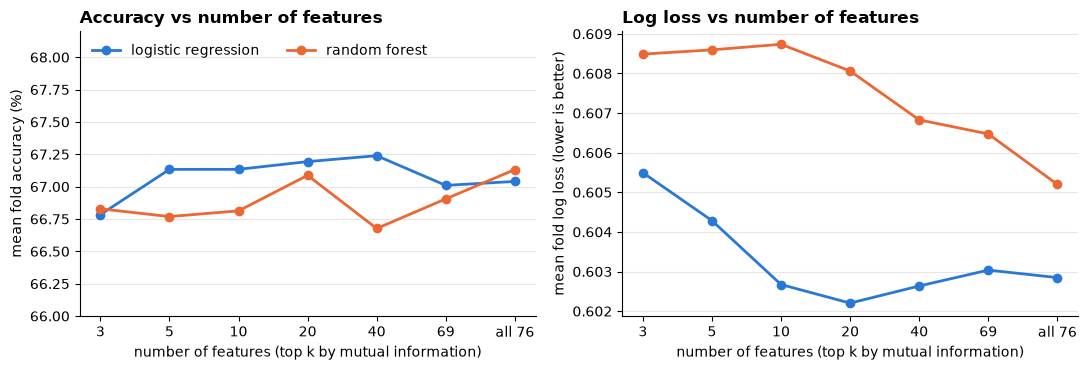

chosen k = 10 (mean fold log loss 0.6027, best 0.6022)


In [7]:
order = [str(k) for k in ks]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, label in ((axes[0], "accuracy", "mean fold accuracy (%)"), (axes[1], "log_loss", "mean fold log loss (lower is better)")):
    for name, color in (("logistic regression", BLUE), ("random forest", ORANGE)):
        vals = kcurve.loc[name].reindex(order)[metric] * (100 if metric == "accuracy" else 1)
        ax.plot(range(len(order)), vals.values, marker="o", lw=2, color=color, label=name)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    ax.set_xlabel("number of features (top k by mutual information)"); ax.set_ylabel(label)
    ax.grid(axis="y", color="#e6e5e1")
axes[0].set_ylim(66, 68.2)   # differences are under 0.6 points; a wider range keeps them in proportion
axes[0].legend(loc="upper left", ncol=2); axes[0].set_title("Accuracy vs number of features")
axes[1].set_title("Log loss vs number of features")
plt.tight_layout(); plt.show()

# smallest k within 0.002 log loss of the best, for logistic regression (prefer fewer features)
lr_curve = kcurve.loc["logistic regression"].reindex(order)
best_ll = lr_curve["log_loss"].min()
k_best = next(int(k) for k in order if k != "all 76" and lr_curve.loc[k, "log_loss"] <= best_ll + 0.002)
print(f"chosen k = {k_best} (mean fold log loss {lr_curve.loc[str(k_best), 'log_loss']:.4f}, best {best_ll:.4f})")

### Step 7: final check on validation: selected features vs all 76
The final feature set is the top-k by mutual information on **all training seasons**. Each model keeps the settings chosen in its own notebook (05, 06, 08). Training time is reported too.

In [8]:
selected = list(mi_train.index[:k_best])
print(f"selected {len(selected)} features:", selected)

models = {"logistic regression (C=0.01)": lambda: lr_model(0.01),
          "random forest (depth 10, leaf 20)": rf_model,
          "linear SVM (C=0.001)": lambda: svm_model("linear", 0.001),
          "RBF SVM (C=0.1, gamma=0.001)": lambda: svm_model("rbf", 0.1, 0.001)}
import warnings
warnings.filterwarnings("ignore", message=".*probability.*deprecated.*", category=FutureWarning)  # SVC(probability=True), see notebook 08

rows = []
for name, make in models.items():
    for label, cols in (("all 76", feature_cols), (f"selected {len(selected)}", selected)):
        t0 = time.time()
        m = make().fit(X.loc[is_train, cols], y[is_train])
        secs = time.time() - t0
        for part, mask in (("train", is_train), ("validation", is_val)):
            r = evaluate(name, y[mask], m.predict_proba(X.loc[mask, cols])[:, 1])
            rows.append({"model": name, "features": label, "split": part, "accuracy": r["accuracy"],
                         "roc_auc": r["roc_auc"], "log_loss": r["log_loss"], "fit_seconds": secs})
final = pd.DataFrame(rows)
table = final.pivot_table(index=["model", "features"], columns="split",
                          values=["accuracy", "roc_auc", "log_loss"], sort=False)
table[("gap", "train - validation")] = table[("accuracy", "train")] - table[("accuracy", "validation")]
table[("fit", "seconds")] = final.groupby(["model", "features"], sort=False)["fit_seconds"].first()
table.round(4)

selected 10 features: ['ELO_PROB_HOME', 'DIFF_SEASON_W_PCT', 'DIFF_PLUS_MINUS_LAST10', 'DIFF_WIN_LAST10', 'ELO_HOME', 'DIFF_PLUS_MINUS_LAST5', 'HOME_SEASON_W_PCT', 'AWAY_SEASON_W_PCT', 'HOME_ST_HOME_W_PCT', 'ELO_AWAY']


accuracy            roc_auc  \
split                                            train validation   train   
model                             features                                  
logistic regression (C=0.01)      all 76        0.6743     0.6658  0.7198   
                                  selected 10   0.6730     0.6593  0.7155   
random forest (depth 10, leaf 20) all 76        0.7377     0.6654  0.8101   
                                  selected 10   0.7140     0.6547  0.7837   
linear SVM (C=0.001)              all 76        0.6748     0.6639  0.7188   
                                  selected 10   0.6726     0.6559  0.7145   
RBF SVM (C=0.1, gamma=0.001)      all 76        0.6721     0.6555  0.7151   
                                  selected 10   0.6708     0.6547  0.7115   

                                                         log_loss             \
split                                         validation    train validation   
model                             features                                     
logistic regression (C=0.01)      all 76          0.7029   0.5983     0.6142   
                                  selected 10     0.7018   0.6015     0.6143   
random forest (depth 10, leaf 20) all 76          0.7023   0.5356     0.6143   
                                  selected 10     0.6981   0.5517     0.6175   
linear SVM (C=0.001)              all 76          0.7032   0.5995     0.6136   
                                  selected 10     0.7011   0.6025     0.6150   
RBF SVM (C=0.1, gamma=0.001)      all 76          0.7014   0.6046     0.6169   
                                  selected 10     0.6995   0.6049     0.6170   

                                                             gap      fit  
split                                         train - validation  seconds  
model                             features                                 
logistic regression (C=0.01)      all 76                  0.0085   0.1389  
                                  selected 10             0.0137   0.0242  
random forest (depth 10, leaf 20) all 76                  0.0723   0.4360  
                                  selected 10             0.0592   0.2484  
linear SVM (C=0.001)              all 76                  0.0109  38.1058  
                                  selected 10             0.0167  18.4010  
RBF SVM (C=0.1, gamma=0.001)      all 76                  0.0166  58.2211  
                                  selected 10             0.0161  32.2715

### Step 8: observation
Observation: **Redundancy.** 10 feature pairs are correlated above 0.95: our own season win % and the standings win % are the same information (r = 0.9999), games played appears four times, and `DIFF_ELO` is almost the same as `ELO_PROB_HOME`. Dropping one of each leaves 69 features.

**Which features matter.** Every method puts Elo and win-rate differences on top (mutual information: `ELO_PROB_HOME`, `DIFF_SEASON_W_PCT`, `DIFF_PLUS_MINUS_LAST10`; L1 and permutation importance: `DIFF_ELO` first by far). The three methods share only one feature in their top 10 (`DIFF_WIN_LAST10`), because many features are near-copies and each method picks a different member of the same group (for example `ELO_PROB_HOME` vs `DIFF_ELO`). L1 at its best C (0.03) keeps 34 of the 76 features, and with only 5 features (C = 0.003) its fold log loss is 0.6060 vs 0.6015 at best.

**How many features do we need.** Logistic regression with only the top 3 features reaches 66.78% mean fold accuracy, against 67.04% with all 76. Its best fold log loss is at 20 features (0.6022 vs 0.6028 with all 76). The differences are under half a point, so almost all the signal sits in a few team-strength features. For the random forest, more features raise training accuracy (70.5% with 3 features, 74.3% with all 76) while fold accuracy stays between 66.7% and 67.1%: the extra features mostly feed overfitting. Its log loss does improve a little with more features (0.6085 to 0.6052).

**Validation check (10 selected features vs all 76).** Accuracy drops slightly for every model: logistic regression 66.58% to 65.93%, random forest 66.54% to 65.47%, linear SVM 66.39% to 65.59%, RBF SVM 65.55% to 65.47%. Log loss is almost unchanged (within 0.004). The random forest's train-validation gap shrinks from 7.2 to 5.9 points, and both SVMs train about twice as fast (linear 34s to 18s, RBF 52s to 31s).

**Conclusion.** Feature selection does not improve accuracy. It shows that about 10 team-strength features (Elo and win-rate differences) carry almost all of the signal in our 76 features, which explains why every model stops at about 66%: the models agree because the information is the same.

**Recommendation.** Keep all 76 features for the final models (or drop only the 7 redundant ones), because the 10-feature set costs 0.1 to 1 point of validation accuracy. The 10-feature set is worth trying for KNN, which is distance-based, and as a faster option for the SVMs. To get past 66% we need new information, such as player availability, not fewer features.